# Part 1: BST Implementation

In [1]:
class BST:
    def __init__(self, key_input = None):
        self.left = None
        self.right = None
        self.key = None
    
        if isinstance(key_input, (list, tuple)): #if we pass a list or a tuple
            for key in key_input:
                self.insert(key)
        #If a single item is passed instead of a list
        elif key_input is not None:
            self.insert(key_input)

    def insert(self, key):
        if self.key is None:
            self.key = key
            return
        if key <= self.key:
            if self.left is None:
                self.left = BST(key)
            else:
                self.left.insert(key)
        else:
            if self.right is None:
                self.right = BST(key)
            else:
                self.right.insert(key)

    def search(self, key, comparisons = 0):
        if self.key is None:
            return comparisons

        comparisons += 1

        if key == self.key:
            return comparisons

        if key < self.key:
            if self.left is None:
                return comparisons
            return self.left.search(key, comparisons)
        else:
            if self.right is None:
                return comparisons
            return self.right.search(key, comparisons)
        
    def height(self):
        if self.key is None:
            return -1  #An empty tree has a height of -1
        
        left_height = self.left.height() if self.left else -1
        right_height = self.right.height() if self.right else -1
        
        return 1 + max(left_height, right_height)

    def node_depths(self, current_depth = 0, depth = None):
        #Initialize the dictionary on the very first call
        if depth is None:
            depth = {}
            
        #Record the depth of the current sub-tree root node
        if self.key is not None:
            depth[self.key] = current_depth
            #Recursively tell the children their depth is (current + 1)
            if self.left:
                self.left.node_depths(current_depth + 1, depth)
            if self.right:
                self.right.node_depths(current_depth + 1, depth)
    
        return depth

    def inorder(self):
        if self.key is None:
            return []
        
        left_keys = self.left.inorder() if self.left else []
        right_keys = self.right.inorder() if self.right else []
        
        return left_keys + [self.key] + right_keys

keys = [50, 30, 70, 20, 40, 60, 80, 35, 45]
tree = BST(keys)

print("Original List:", keys)
print("Ordered List:", tree.inorder())

#Find comparisons made
comp35 = tree.search(35)
print(f"\nComparisons made searching for 35: {comp35}")
comp60 = tree.search(60)
print(f"\nComparisons made searching for 60: {comp60}")
comp80 = tree.search(80)
print(f"\nComparisons made searching for 80: {comp80}")

all_depths = tree.node_depths()
print(f"\nAll node depths:", all_depths)

print(f"\nHeight of Tree:")
total_height = tree.height()
print(f"{total_height}")

Original List: [50, 30, 70, 20, 40, 60, 80, 35, 45]
Ordered List: [20, 30, 35, 40, 45, 50, 60, 70, 80]

Comparisons made searching for 35: 4

Comparisons made searching for 60: 3

Comparisons made searching for 80: 3

All node depths: {50: 0, 30: 1, 20: 2, 40: 2, 35: 3, 45: 3, 70: 1, 60: 2, 80: 2}

Height of Tree:
3


# Part 2: Insertion-Order Experiments

In [2]:
import random as rd

#3 strategies
def ascending_bst(N):
    if N < 1:
        raise ValueError("N must be at least 1")

    bst_in_order = BST()

    for i in range (1, N + 1):
        bst_in_order.insert(i)
    return bst_in_order

def gen_random(N, seed):
    if N < 0:
        raise ValueError("N must be positive")
        
    rd.seed(seed)
    return rd.sample(range(1, N + 1), N)

def random_bst(N, seed):
    if N < 1:
        raise ValueError("N must be at least 1")
    bst_random = BST()
    rdm_stack = gen_random(N, seed)
    for i in range(0, N):
        bst_random.insert(rdm_stack.pop())
    return bst_random

def balanced_bst(bst, lst):
    if not lst:
        return bst
    else:
        middle_node = len(lst) // 2
        bst.insert(lst[middle_node])
        left_list = lst[:middle_node]
        right_list = lst[middle_node + 1:]
        balanced_bst(bst, left_list)
        balanced_bst(bst, right_list)
    return bst

## Experiments

In [3]:
#Average Node Height
N_val = [100, 500, 1000, 2000]

#Dictionary to hold the results for plotting or printing later
height_results = {}

for N in N_val:
    #Ascending
    exp_ascending_bst = ascending_bst(N)
    
    #Random BSTs (10 trials per N)
    random_heights = []
    for i in range(14, 24):
        exp_random_bst = random_bst(N, i)
        random_heights.append(exp_random_bst.height())
    avg_random_height = sum(random_heights) / len(random_heights)
    
    #Balanced BST
    lst = list(range(1, N + 1))
    bst_instance = BST()
    exp_balanced_bst = balanced_bst(bst_instance, lst)
    
    #Storing results
    height_results[N] = {
        "ascending": exp_ascending_bst.height(),
        "random_avg": avg_random_height,
        "balanced": exp_balanced_bst.height() if exp_balanced_bst else bst_instance.height()
    }
    
#print as a table
print(f"{'N':<8} | {'Ascending Height':<20} | {'Random Avg Height':<18} | {'Balanced Height':<18}")
print("-" * 73)
for N, hts in height_results.items():
    print(f"{N:<8} | {hts['ascending']:<20} | {hts['random_avg']:<18.1f} | {hts['balanced']:<18}")

N        | Ascending Height     | Random Avg Height  | Balanced Height   
-------------------------------------------------------------------------
100      | 99                   | 12.8               | 6                 
500      | 499                  | 18.7               | 8                 
1000     | 999                  | 21.3               | 9                 
2000     | 1999                 | 22.6               | 10                


In [4]:
#Average Node Depth
N_val = [100, 500, 1000, 2000]
depth_results = {}
depths_dict = tree.node_depths()
avg_depth = sum(depths_dict.values()) / N

for N in N_val:
    #Ascending
    tree_a = ascending_bst(N)
    total_depth_a = tree_a.node_depths() 
    avg_depth_a = sum(total_depth_a.values()) / N
    
    #Random
    random_avg_depths = []
    for seed in range(1, 11):
        tree_b = random_bst(N, seed)
        depths_b = tree_b.node_depths()
        random_avg_depths.append(sum(depths_b.values()) / N)
    
    final_avg_depth_b = sum(random_avg_depths) / 10
    
    #Balance
    bst_instance = BST()
    lst = list(range(1, N + 1))
    tree_c = balanced_bst(bst_instance, lst)
    depths_c = tree_c.node_depths()
    avg_depth_c = sum(depths_c.values()) / N

    depth_results[N] = {
        "ascending": avg_depth_a,
        "random_avg": final_avg_depth_b,
        "balanced": avg_depth_c
    }

#print as a table
print(f"{'N':<8} | {'Ascending Avg Depth':<20} | {'Random Avg Depth':<18} | {'Balanced Avg Depth':<18}")
print("-" * 73)
for N, metrics in depth_results.items():
    print(f"{N:<8} | {metrics['ascending']:<20.2f} | {metrics['random_avg']:<18.2f} | {metrics['balanced']:<18.2f}")

N        | Ascending Avg Depth  | Random Avg Depth   | Balanced Avg Depth
-------------------------------------------------------------------------
100      | 49.50                | 6.57               | 4.80              
500      | 249.50               | 9.66               | 7.00              
1000     | 499.50               | 11.10              | 7.99              
2000     | 999.50               | 12.02              | 8.98              


In [5]:
#Average Search Comparisons
N_val = [100, 500, 1000, 2000]
search_results = {}

for N in N_val:
    keys = list(range(1, N + 1))
    
    #Ascending
    tree_A = ascending_bst(N)
    total_comps_a = sum((tree_A.search(k)+1) for k in keys)
    avg_comps_a = total_comps_a / N
    
    #Random
    random_avg_comps = []
    for seed in range(14, 24):
        tree_B = random_bst(N, seed)
        total_comps_b = sum(tree_B.search(k) for k in keys)
        random_avg_comps.append(total_comps_b / N)
        
    final_avg_comps_b = sum(random_avg_comps) / 10
                                                    
    #Balance
    bst_instance = BST()
    tree_C = balanced_bst(bst_instance, keys)
    total_comps_c = sum(tree_C.search(k) for k in keys)
    avg_comps_c = total_comps_c / N
    
    search_results[N] = {
        "ascending": avg_comps_a,
        "random_avg": final_avg_comps_b,
        "balanced": avg_comps_c
    }
    
print(f"{'N':<8} | {'Ascending Avg Comps':<20} | {'Random Avg Comps':<18} | {'Balanced Avg Comps':<18}")
print("-" * 73)
for N, metrics in search_results.items():
    print(f"{N:<8} | {metrics['ascending']:<20.1f} | {metrics['random_avg']:<18.1f} | {metrics['balanced']:<18.1f}")

N        | Ascending Avg Comps  | Random Avg Comps   | Balanced Avg Comps
-------------------------------------------------------------------------
100      | 51.5                 | 7.8                | 5.8               
500      | 251.5                | 10.8               | 8.0               
1000     | 501.5                | 12.0               | 9.0               
2000     | 1001.5               | 13.3               | 10.0              


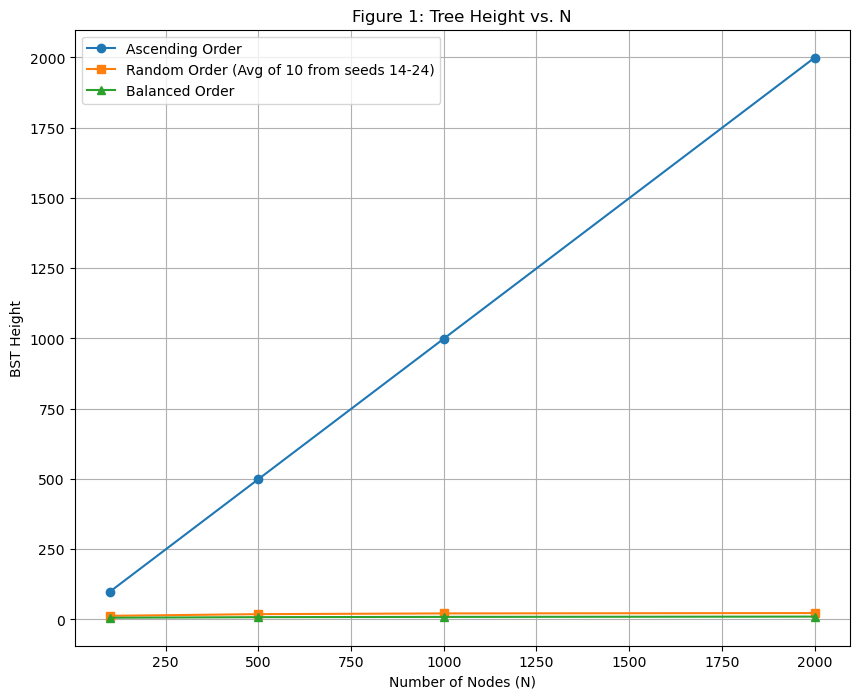

In [6]:
import matplotlib.pyplot as plt

#Figure 1: Tree Height vs N
plt.figure(figsize = (10, 8))
plt.plot(N_val, [height_results[n]["ascending"] for n in N_val], 
         label = "Ascending Order", marker = 'o')
plt.plot(N_val, [height_results[n]["random_avg"] for n in N_val],
         label = "Random Order (Avg of 10 from seeds 14-24)", marker = 's')
plt.plot(N_val, [height_results[n]["balanced"] for n in N_val], 
         label = "Balanced Order", marker = '^')

plt.title("Figure 1: Tree Height vs. N")
plt.xlabel("Number of Nodes (N)")
plt.ylabel("BST Height")
plt.grid(True)
plt.legend()
plt.show()

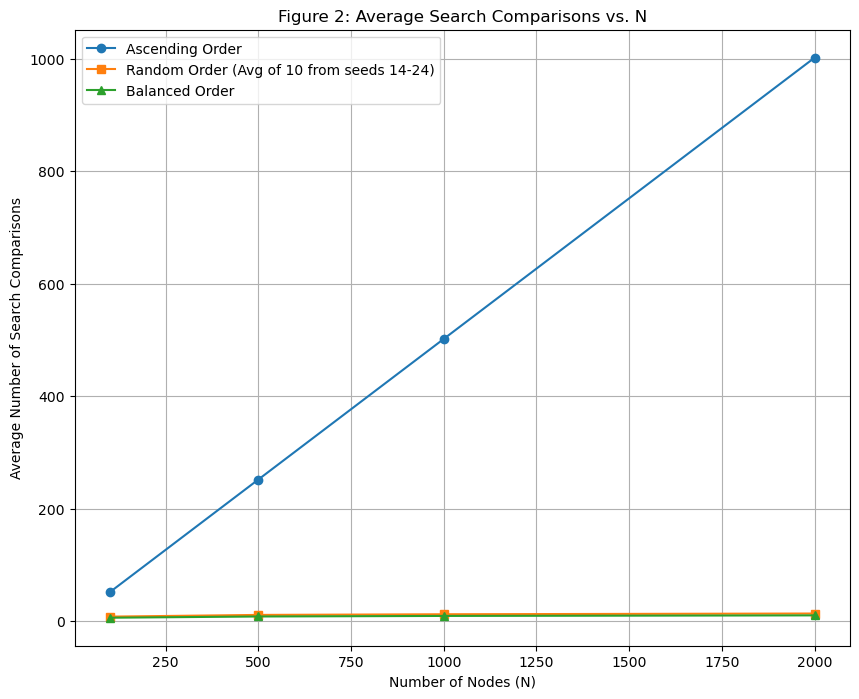

In [7]:
#Figure 2: Average Search Comparisons vs. N
plt.figure(figsize = (10, 8))
plt.plot(N_val, [search_results[n]["ascending"] for n in N_val], 
         label = "Ascending Order", marker = 'o')
plt.plot(N_val, [search_results[n]["random_avg"] for n in N_val],
         label = "Random Order (Avg of 10 from seeds 14-24)", marker = 's')
plt.plot(N_val, [search_results[n]["balanced"] for n in N_val], 
         label = "Balanced Order", marker = '^')

plt.title("Figure 2: Average Search Comparisons vs. N")
plt.xlabel("Number of Nodes (N)")
plt.ylabel("Average Number of Search Comparisons")
plt.grid(True)
plt.legend()
plt.show()

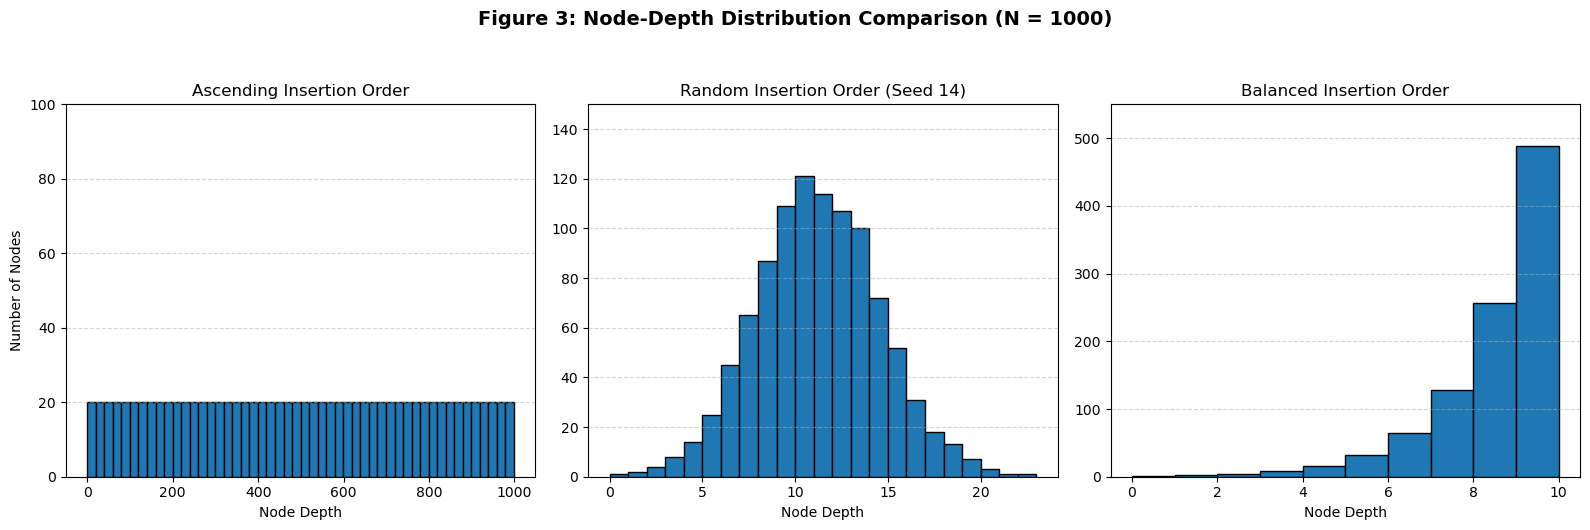

In [8]:
#Figure 3: Node Depth Distribution

N = 1000
keys = list(range(1, N + 1))

#Build the three trees (using seed 14 as your random trial)
tree_ascending = ascending_bst(N)
tree_random = random_bst(N, seed = 14)

bst_instance = BST()
tree_balanced = balanced_bst(bst_instance, keys)
final_tree_balanced = tree_balanced if tree_balanced else bst_instance

#Extract the list of depths for all nodes
depths_ascending = list(tree_ascending.node_depths().values())
depths_random = list(tree_random.node_depths().values())
depths_balanced = list(final_tree_balanced.node_depths().values())

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# --- Plot 1: Ascending BST ---
axes[0].hist(depths_ascending, bins = 50, edgecolor = 'black')
axes[0].set_title('Ascending Insertion Order')
axes[0].set_xlabel('Node Depth')
axes[0].set_ylabel('Number of Nodes')
axes[0].set_ylim(0, 100)
axes[0].grid(axis = 'y', linestyle = '--', alpha = 0.5)

# --- Plot 2: Random BST ---
r_bins = range(min(depths_random), max(depths_random) + 2)
axes[1].hist(depths_random, bins = r_bins, edgecolor = 'black')
axes[1].set_title('Random Insertion Order (Seed 14)')
axes[1].set_xlabel('Node Depth')
axes[1].set_ylim(0, 150)
axes[1].grid(axis = 'y', linestyle = '--', alpha = 0.5)

# --- Plot 3: Balanced BST ---
b_bins = range(min(depths_balanced), max(depths_balanced) + 2)
axes[2].hist(depths_balanced, bins = b_bins, edgecolor = 'black')
axes[2].set_title('Balanced Insertion Order')
axes[2].set_xlabel('Node Depth')
axes[2].set_ylim(0, 550)
axes[2].grid(axis = 'y', linestyle='--', alpha = 0.5)

plt.suptitle('Figure 3: Node-Depth Distribution Comparison (N = 1000)', fontsize = 14, fontweight = 'bold', y = 1.05)
plt.tight_layout()
plt.show()